# Sun's Blessing (Templar)

Sun's Blessing is a free self-buff. For 180 s it adds the same bonus to all five attributes,
to armor and to weapon value. The cooldown is 55 s, but a recast simply refreshes the existing
buff, so the uptime is 100%.

| | |
|---|---|
| Class | Templar |
| Target | Self only |
| Cost | none |
| Cooldown | 55 s (separate `SK_SUNS_BLESSING` marker) |
| Landing roll | none |
| Duration | 180 s |
| Effect | `attrib[0..5][1]`, `armor[1]`, `weapon[1]` += bonus |
| Power | `unbuffed_skill_power`: the modified skill minus the part contributed by spell attribute bonuses |
| Source | `server/src/driver/skill/templar.rs::skill_suns_blessing`; `driver/skill/common.rs::unbuffed_skill_power` |

---

# Formula

$$
\text{bonus} = \operatorname{clamp}\!\left(3\left(\lfloor p_u/10 \rfloor + 2\right),\ 3,\ 90\right)
$$

$p_u$ is the *unbuffed* power: the modified skill with every active spell's attribute bonus
removed from the skill's three governing attributes. Without this, the buff's own +bonus to
attributes would feed back into the next recast.

$$
p_u = p - \left(\left\lfloor \tfrac{\sum a_5}{5} \right\rfloor - \left\lfloor \tfrac{\max(0,\ \sum (a_5 - a_\text{spell}))}{5} \right\rfloor\right)
$$

Each skill is derived from three attributes divided by 5, so +bonus to every attribute is worth
about $\tfrac{3}{5}\,\text{bonus}$ on **every** skill.

| Quantity | Breakpoint |
|---|---|
| Steps | +3 every 10 skill points |
| Raise cap | +36 at skill 105 (+42 at 120) |
| Ceiling | +90 at $p_u \ge 280$ |

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mag_model as mm

mm.apply_style()
P = mm.SKILL_RANGE
BUFF_S = 180
COOLDOWN_S = 55

# Model

In [2]:
def sun_bonus(p_unbuffed):
    return mm.clamp((mm.idiv(p_unbuffed, 10) + 2) * 3, 3, 90)


def unbuffed_skill_power(skill5, attribs5, spell_bonus):
    """`unbuffed_skill_power` for one skill: attribs5 / spell_bonus are its three attributes."""
    buffed = sum(attribs5)
    base = sum(a - s for a, s in zip(attribs5, spell_bonus))
    return skill5 - (buffed // 5 - max(0, base) // 5)


def incoming_reduction(p, wv, base_armor=20, strength=80):
    """Fraction of one attacker's per-hit damage removed by the armor bonus."""
    b = sun_bonus(p)
    before = mm.melee_hit_hp(wv, strength, base_armor)
    after = mm.melee_hit_hp(wv, strength, base_armor + np.asarray(b))
    return 1 - after / before


def outgoing_gain(p, wv, strength=80, armor=20):
    """Per-hit damage multiplier from +bonus weapon value and +bonus STR."""
    b = np.atleast_1d(sun_bonus(p))
    after = np.array([mm.melee_hit_hp(wv + x, strength + x, armor) for x in b])
    out = after / mm.melee_hit_hp(wv, strength, armor)
    return mm._scalar(out if np.ndim(p) else out[0])

# Validation

- `suns_blessing_grants_bonuses_and_a_separate_cooldown`: power 40 gives +18 to every attribute,
  armor and weapon. The buff lasts `TICKS*180`, the cooldown `TICKS*55`, and a recast during the
  cooldown keeps the same item.
- `suns_blessing_bonus_is_capped`: power 1000 gives armor +90.
- `unbuffed_skill_power_strips_spell_attribute_bonuses`: skill 69 with attributes at 65 stays 69.
  With +15 from a spell on each attribute it becomes 60.

In [3]:
assert sun_bonus(40) == 18 and sun_bonus(1000) == 90
assert mm.TICKS * BUFF_S == 6480 and mm.TICKS * COOLDOWN_S == 1980
assert unbuffed_skill_power(69, (65, 65, 65), (0, 0, 0)) == 69
assert unbuffed_skill_power(69, (65, 65, 65), (15, 15, 15)) == 60
assert sun_bonus(105) == 36 and sun_bonus(120) == 42 and sun_bonus(0) == 6
print("Sun's Blessing model OK")

Sun's Blessing model OK


# Plots

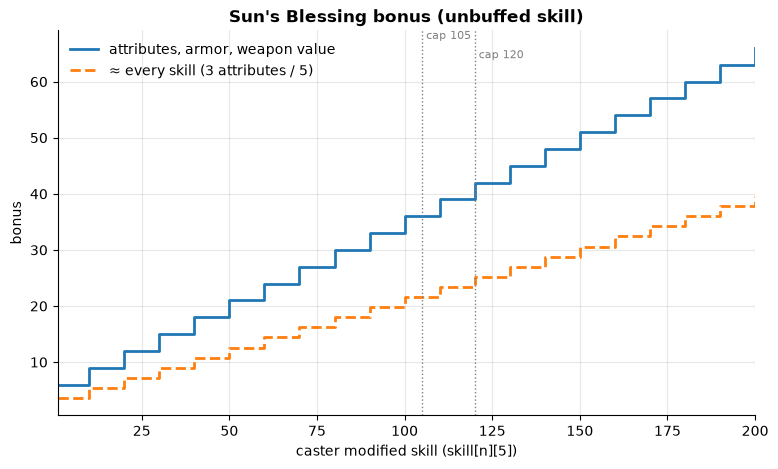

In [4]:
fig, ax = plt.subplots()
ax.step(P, sun_bonus(P), where="post", label="attributes, armor, weapon value")
ax.step(P, sun_bonus(P) * 3 / 5, where="post", ls="--", label="≈ every skill (3 attributes / 5)")
mm.skill_axis(ax, "bonus", "Sun's Blessing bonus (unbuffed skill)")
mm.mark_caps(ax)
ax.legend()

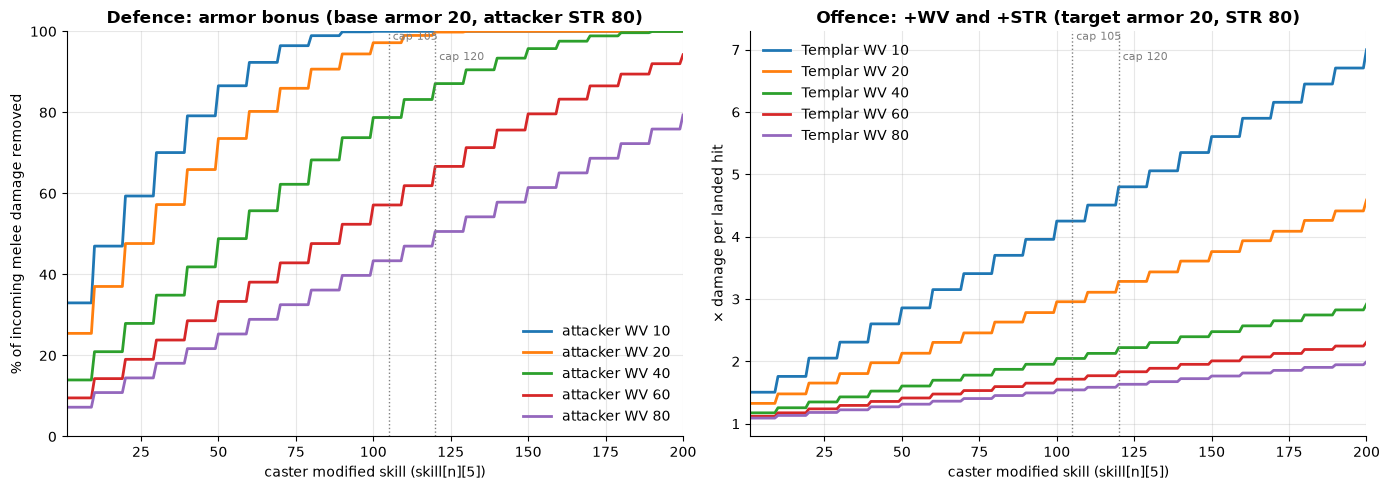

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for wv in mm.WV_SWEEP:
    ax.plot(P, 100 * incoming_reduction(P, wv), label=f"attacker WV {wv}")
mm.skill_axis(ax, "% of incoming melee damage removed", "Defence: armor bonus (base armor 20, attacker STR 80)")
ax.set_ylim(0, 100)
mm.mark_caps(ax)
ax.legend()

ax = axes[1]
for wv in mm.WV_SWEEP:
    ax.plot(P, outgoing_gain(P, wv), label=f"Templar WV {wv}")
mm.skill_axis(ax, "× damage per landed hit", "Offence: +WV and +STR (target armor 20, STR 80)")
mm.mark_caps(ax)
ax.legend()
plt.tight_layout()

# Observations

- **Free, permanent, and very large.** At skill 105 the buff adds +36 to every attribute, armor
  and weapon value. That is about +21 to every skill, including Weapon Skill, Resist and
  Immunity. It costs nothing, lasts 180 s, and can be refreshed after 55 s. `add_spell` replaces a
  same-temp spell unless the new one is weaker, and an equal-power recast is not weaker, so the
  uptime is 100%.
- **Defence.** Against base armor 20, +36 armor removes 79% of a WV-40 STR-80 attacker's damage
  per hit (10.75 → 2.3 HP) and 57% of a WV-60 attacker's. Weak attackers (WV ≤ 20) are nullified
  almost completely from skill ~100.
- **Offence.** +36 WV and +36 STR double a WV-40 Templar's damage per landed hit against armor 20
  (10.75 → 22.0 HP, ×2.05). The +21 Weapon Skill also moves an even fight from 60% to 90% to hit
  (Δ +21 → chance 18) and drops the enemy from 60% to 30% (Δ −21 → chance 6).
- **The unbuffed power works as intended.** The buff's own attribute bonus is stripped before the
  bonus is computed, so recasting does not compound. Other attribute buffs (Bless, Sun's Blessing
  itself) do not raise it either.
- **The doc comment is stale.** It says the cooldown is "slightly shorter than the buff
  duration". The cooldown is 55 s against a 180 s buff, so the cooldown never limits anything.
- **Balance suggestions.** Charge a resource, or shorten the buff to below the cooldown
  (for example 45 s buff, 55 s cooldown). Or split the bonus so attributes, armor and weapon do
  not all scale with the same number. A third of the current bonus on armor and weapon would
  still be a strong buff.